# Used-Vehicle Price Prediction in Sri Lanka
### Black-box Ensembles, a Glass-box Explainable Boosting Machine and Explainable AI

**MSc Machine Learning · Final Assignment**

**Wijesundara V.D.A.R. 269221H**

**Target:** Advertised vehicle price (LKR) · **Random seed:** 42

This notebook asks two linked questions: *how accurately can advertised vehicle prices be predicted*, and *how can those predictions be explained*. Six regressors, from a median baseline through black-box tree ensembles to a glass-box **Explainable Boosting Machine (EBM)**, are trained, tuned, selected and tested under one leakage-safe protocol. The fitted models are then explained with complementary global and local XAI techniques, so that accuracy and interpretability can be weighed together.

| Section | Content |
|---|---|
| 1–2 | Data, environment and group-disjoint partitions |
| 3–4 | Input representations, candidate models and metrics |
| 5–7 | Validation comparison, group-aware tuning and model selection |
| 8–9 | Held-out test evaluation and error analysis |
| 10 | Explainable AI: global importance, EBM shape functions and a local explanation |
| 11–12 | Model export, conclusions and limitations |

## 1. Dataset and experimental environment

The cleaned dataset from Notebook 01 is used for all regression experiments. Library versions are printed for reproducibility.

In [1]:
from pathlib import Path
from functools import partial
import json, time, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import joblib
import sklearn, xgboost, lightgbm, interpret
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from interpret.glassbox import ExplainableBoostingRegressor

SEED = 42
sns.set_theme(style='whitegrid', palette='deep', context='notebook')
plt.rcParams.update({'figure.figsize':(9,4.5), 'axes.spines.top':False,
                     'axes.spines.right':False,'figure.dpi':110})
pd.set_option('display.max_columns',25)
MILLIONS = FuncFormatter(lambda value, _: f'{value/1e6:,.0f}M')  # LKR axis labels
# EBM handles missing numeric values natively; this notice only concerns InterpretML's own plots.
warnings.filterwarnings('ignore', message='Missing values detected')
print(f'scikit-learn {sklearn.__version__} · XGBoost {xgboost.__version__} · '
      f'LightGBM {lightgbm.__version__} · InterpretML {interpret.__version__}')

scikit-learn 1.8.0 · XGBoost 3.4.1 · LightGBM 4.7.0 · InterpretML 0.7.8


In [2]:
# Run this notebook from the project folder, after Notebook 01 has produced the cleaned CSV.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'vehicle_ml_outputs' / 'cleaned_vehicle_data.csv').is_file():
    raise FileNotFoundError('Cleaned dataset not found. Execute Notebook 01 first '
                            '(and start Jupyter from the project folder).')

OUTPUT_DIR = PROJECT_DIR / 'vehicle_ml_outputs'
CLEAN_CSV = OUTPUT_DIR / 'cleaned_vehicle_data.csv'
TARGET = 'PriceLKR'
CAT = ['Brand', 'Model', 'Edition', 'Transmission', 'FuelType', 'BodyType', 'Negotiable']
NUM = ['ManufactureYear', 'EngineCC', 'MileageKM']
FEATURES = CAT + NUM

df = pd.read_csv(CLEAN_CSV)
assert set(FEATURES + [TARGET]).issubset(df.columns)
for column in CAT:
    df[column] = df[column].fillna('Unknown').astype(str)
for column in NUM + [TARGET]:
    df[column] = pd.to_numeric(df[column], errors='coerce')
assert df[TARGET].notna().all() and df[TARGET].gt(0).all() and len(df) > 1000

profile = pd.DataFrame({
    'Observations': [len(df)],
    'Predictors': [len(FEATURES)],
    'Median price (LKR)': [df[TARGET].median()],
    'Missing numeric cells': [int(df[NUM].isna().sum().sum())],
})
display(profile.style.format({'Median price (LKR)': '{:,.0f}'}).hide(axis='index'))
display(df.head(4))

Observations,Predictors,Median price (LKR),Missing numeric cells
8554,10,"10,690,000",115


,Brand,Model,Edition,Transmission,FuelType,BodyType,Negotiable,ManufactureYear,EngineCC,MileageKM,PriceLKR
0,Audi,A3,Unknown,Automatic,Petrol,Saloon,Yes,2023,1500.0,0.0,20500000.0
1,Audi,A3,Sport Back S Line,Automatic,Petrol,Hatchback,Yes,2023,1000.0,11000.0,18500000.0
2,Ford,Laser,Gl,Manual,Petrol,Saloon,Yes,1988,1500.0,250000.0,1000000.0
3,Honda,Clarity,Unknown,Manual,Petrol,Coupé/Sports,Yes,2005,1000.0,20000.0,1000000.0


## 2. Partitioning and leakage controls

`GroupShuffleSplit` assigns identical feature combinations to disjoint training, validation and test partitions (approximately 70% / 15% / 15%).

In [3]:
feature_groups = pd.util.hash_pandas_object(df[FEATURES],index=False)
outer = GroupShuffleSplit(n_splits=1,test_size=.15,random_state=SEED)
trainval_idx,test_idx = next(outer.split(df,groups=feature_groups))
inner = GroupShuffleSplit(n_splits=1,test_size=.17647,random_state=SEED+1)
train_local,val_local = next(inner.split(trainval_idx,groups=feature_groups.iloc[trainval_idx]))
train_idx,val_idx = trainval_idx[train_local],trainval_idx[val_local]

g_train=set(feature_groups.iloc[train_idx]);g_val=set(feature_groups.iloc[val_idx]);g_test=set(feature_groups.iloc[test_idx])
assert g_train.isdisjoint(g_val) and g_train.isdisjoint(g_test) and g_val.isdisjoint(g_test)
# Reproducibility check: the seeded grouped split must match the reported partition sizes
# quoted in Section 8 and the report.
assert (len(train_idx),len(val_idx),len(test_idx))==(5995,1274,1285), 'Grouped split changed'
assert len(trainval_idx)==len(train_idx)+len(val_idx)==7269
X_train,y_train = df.iloc[train_idx][FEATURES],df.iloc[train_idx][TARGET]
X_val,y_val = df.iloc[val_idx][FEATURES],df.iloc[val_idx][TARGET]
X_trainval,y_trainval = df.iloc[trainval_idx][FEATURES],df.iloc[trainval_idx][TARGET]
X_test,y_test = df.iloc[test_idx][FEATURES],df.iloc[test_idx][TARGET]
cv_groups = feature_groups.iloc[train_idx]

partition = pd.DataFrame({'Partition':['Train','Validation','Test'],
                          'Rows':[len(train_idx),len(val_idx),len(test_idx)],
                          'Unique groups':[len(g_train),len(g_val),len(g_test)]})
display(partition.style.format({'Rows':'{:,}','Unique groups':'{:,}'}).hide(axis='index'))

Partition,Rows,Unique groups
Train,"5,995","5,810"
Validation,"1,274","1,245"
Test,"1,285","1,246"


## 3. Input representations and target scale

Every candidate receives the same ten raw features and the same target in LKR, and returns predictions in LKR, so one training, selection and evaluation loop serves all models. Internally, two representations are used:

| | Black-box models (tree, forest, boosting) | Glass-box EBM |
|---|---|---|
| Categorical features | most-frequent imputation, rare-category-aware one-hot encoding | native nominal terms (no encoding) |
| Numeric features | median imputation with missing indicators, robust scaling | native binning; missing values handled directly |
| Target | log-transformed, back-transformed to LKR | price in **million LKR**, identity link |

The log target stabilises the skewed price distribution for the black-box models. EBM's target scale is instead chosen for interpretability: with an identity link, its intercept plus its per-feature contributions sum exactly to the prediction, so each contribution reads directly as rupees (Section 10). All preprocessing is fitted inside each training fold.

In [4]:
def make_pipeline(regressor):
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', RobustScaler(with_centering=False)),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(
            handle_unknown='infrequent_if_exist',
            min_frequency=15,
            sparse_output=True,
        )),
    ])
    preprocess = ColumnTransformer([
        ('numeric', numeric, NUM),
        ('categorical', categorical, CAT),
    ], sparse_threshold=1.0)
    model = Pipeline([
        ('preprocess', preprocess),
        ('regressor', regressor),
    ])
    return TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1,
    )

In [5]:
EBM_PRICE_UNIT = 1_000_000  # EBM learns and predicts price in million LKR
# partial(np.multiply, ...) rather than lambdas keeps the fitted wrapper picklable.
TO_MILLION_LKR = partial(np.multiply, 1 / EBM_PRICE_UNIT)
FROM_MILLION_LKR = partial(np.multiply, EBM_PRICE_UNIT)

def make_ebm_model(ebm):
    """Raw features go straight to EBM; only the target is rescaled."""
    return TransformedTargetRegressor(
        regressor=ebm, func=TO_MILLION_LKR, inverse_func=FROM_MILLION_LKR,
    )

def build_model(estimator):
    """Wrap any candidate so it accepts raw features and LKR targets."""
    if isinstance(estimator, ExplainableBoostingRegressor):
        return make_ebm_model(estimator)
    return make_pipeline(estimator)

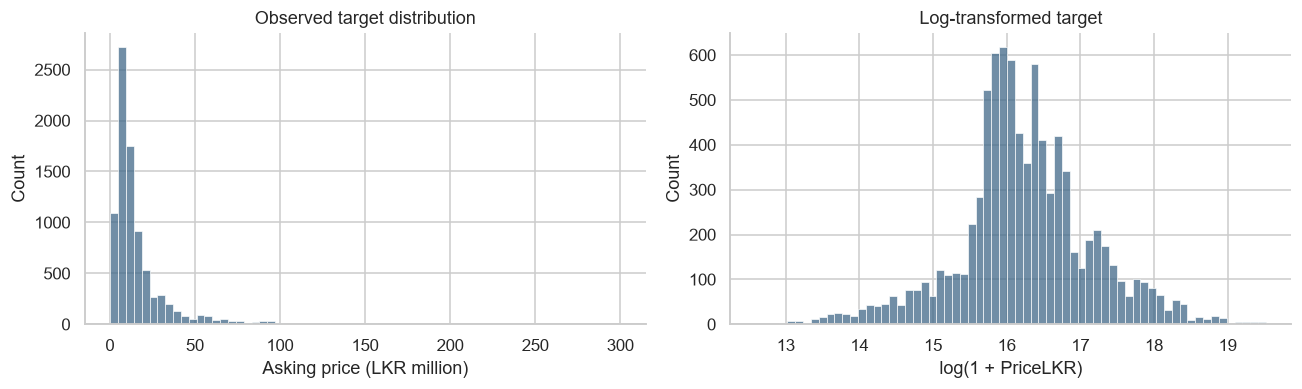

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
sns.histplot(df.PriceLKR / 1e6, bins=65, ax=axes[0], color='#416989')
axes[0].set(xlabel='Asking price (LKR million)', title='Observed target distribution')
sns.histplot(np.log1p(df.PriceLKR), bins=65, ax=axes[1], color='#416989')
axes[1].set(xlabel='log(1 + PriceLKR)', title='Log-transformed target')
plt.tight_layout()
plt.show()

## 4. Regression candidates and evaluation metrics

The six candidates span a range of model complexity and transparency:

- **Median baseline**: a reference point that ignores all features.
- **Decision Tree**: a single tree, readable in principle but deep (maximum depth 18).
- **Random Forest, XGBoost, LightGBM**: bagged and boosted tree ensembles. These are typically the most accurate tabular learners, but they are *black boxes* that need post-hoc explanation.
- **Explainable Boosting Machine (EBM)**: a *glass-box* generalised additive model from InterpretML, beyond the lecture models. It boosts one shallow shape function per feature in round-robin fashion, so its price estimate is a sum of per-feature effects. `interactions=0` keeps every contribution attributable to a single feature, while bagging (`outer_bags=4`) and early stopping on internal validation splits regularise the model. Its settings are fixed in advance.

Models are compared on MAE (primary criterion, in LKR), RMSE, R² and median absolute percentage error.

In [7]:
estimators = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=18, min_samples_leaf=4, min_samples_split=10,
        random_state=SEED,
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=160, max_depth=24, min_samples_leaf=2,
        min_samples_split=4, max_features=.85, n_jobs=2,
        random_state=SEED,
    ),
    'XGBoost': XGBRegressor(
        n_estimators=450, max_depth=7, learning_rate=.055,
        min_child_weight=3, subsample=.85, colsample_bytree=.85,
        reg_lambda=4, tree_method='hist', objective='reg:squarederror',
        n_jobs=2, random_state=SEED,
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=380, num_leaves=31, max_depth=10,
        learning_rate=.05, min_child_samples=25, subsample=.9,
        subsample_freq=1, colsample_bytree=.85, reg_lambda=3,
        verbose=-1, n_jobs=2, random_state=SEED,
    ),
    'EBM': ExplainableBoostingRegressor(
        feature_names=FEATURES,
        feature_types=['nominal'] * len(CAT) + ['continuous'] * len(NUM),
        interactions=0, max_bins=128, outer_bags=4, learning_rate=.04,
        max_rounds=1200, early_stopping_rounds=60, min_samples_leaf=8,
        n_jobs=2, random_state=SEED,
    ),
}

model_family = {
    'Median baseline': 'Reference',
    'Decision Tree': 'Single tree',
    'Random Forest': 'Bagged ensemble (black box)',
    'XGBoost': 'Boosted ensemble (black box)',
    'LightGBM': 'Boosted ensemble (black box)',
    'EBM': 'Additive model (glass box)',
}
pd.DataFrame([
    {'Model': name, 'Estimator': type(estimator).__name__, 'Family': model_family[name],
     'Representation': 'raw features · million-LKR target' if name == 'EBM'
                       else 'one-hot pipeline · log target'}
    for name, estimator in estimators.items()
])

,Model,Estimator,Family,Representation
0,Median baseline,DummyRegressor,Reference,one-hot pipeline · log target
1,Decision Tree,DecisionTreeRegressor,Single tree,one-hot pipeline · log target
2,Random Forest,RandomForestRegressor,Bagged ensemble (black box),one-hot pipeline · log target
3,XGBoost,XGBRegressor,Boosted ensemble (black box),one-hot pipeline · log target
4,LightGBM,LGBMRegressor,Boosted ensemble (black box),one-hot pipeline · log target
5,EBM,ExplainableBoostingRegressor,Additive model (glass box),raw features · million-LKR target


In [8]:
def metrics(y_true, y_pred):
    y_pred = np.maximum(np.asarray(y_pred), 0)
    return {
        'MAE_LKR': mean_absolute_error(y_true, y_pred),
        'RMSE_LKR': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
        'Median_APE_pct': np.median(
            np.abs(np.asarray(y_true) - y_pred)
            / np.maximum(np.asarray(y_true), 1)
        ) * 100,
    }

## 5. Initial validation comparison

Each candidate, EBM included, is trained on the training partition and scored on the validation partition. Placing EBM in the same table shows directly how much accuracy, if any, a fully additive model gives up relative to the black-box ensembles.

In [9]:
validation_rows=[]
base_fitted={}
for name,est in estimators.items():
    t0=time.perf_counter()
    fitted=build_model(est).fit(X_train,y_train)
    scores=metrics(y_val,fitted.predict(X_val))
    validation_rows.append({'Model':name,**scores,'Fit_s':time.perf_counter()-t0,'Experiment':'Configured'})
    base_fitted[name]=fitted
validation=pd.DataFrame(validation_rows).sort_values('MAE_LKR').reset_index(drop=True)
display(validation.style.format({'MAE_LKR':'{:,.0f}','RMSE_LKR':'{:,.0f}',
                                 'R2':'{:.3f}','Median_APE_pct':'{:.1f}',
                                 'Fit_s':'{:.1f}'}).background_gradient(subset=['MAE_LKR'],cmap='Blues_r'))

,Model,MAE_LKR,RMSE_LKR,R2,Median_APE_pct,Fit_s,Experiment
0,XGBoost,"1,871,809","5,453,882",0.927,5.9,2.7,Configured
1,Random Forest,"2,023,708","7,358,898",0.867,5.6,13.7,Configured
2,LightGBM,"2,202,386","6,772,247",0.887,6.7,0.6,Configured
3,Decision Tree,"2,588,351","10,110,665",0.748,6.6,0.2,Configured
4,EBM,"4,881,939","9,720,740",0.767,24.4,7.0,Configured
5,Median baseline,"10,694,016","21,264,576",-0.114,44.2,0.1,Configured


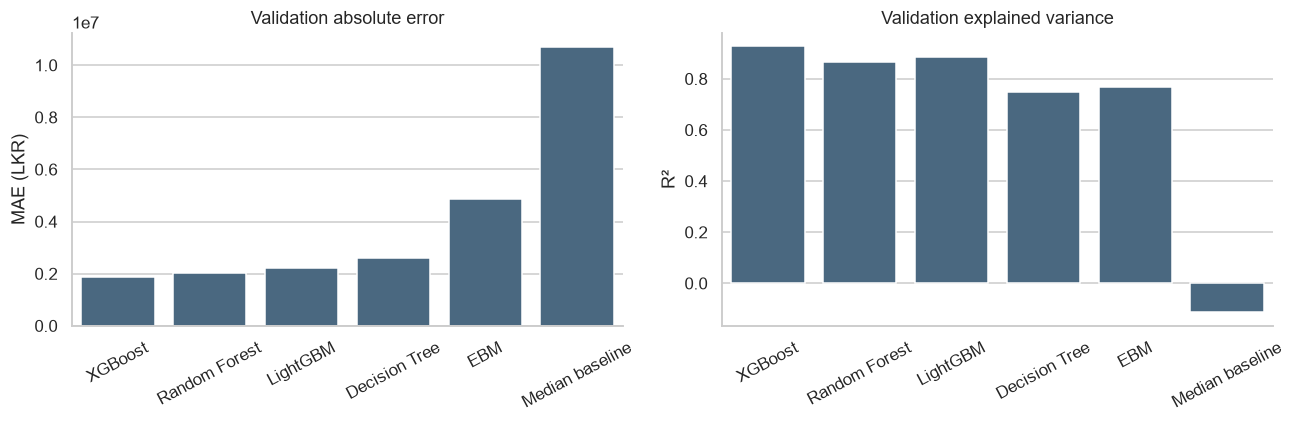

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=validation,x='Model',y='MAE_LKR',ax=ax[0],color='#416989')
ax[0].set(title='Validation absolute error',ylabel='MAE (LKR)',xlabel='')
sns.barplot(data=validation,x='Model',y='R2',ax=ax[1],color='#416989')
ax[1].set(title='Validation explained variance',ylabel='R²',xlabel='')
for a in ax:a.tick_params(axis='x',labelrotation=28)
plt.tight_layout();plt.show()

## 6. Group-aware cross-validation and tuning

The two strongest black-box ensembles undergo three-fold `GroupKFold` and a compact `RandomizedSearchCV` (three parameter combinations each). EBM keeps its fixed configuration: it already chooses its number of boosting rounds by early stopping, and its role in this study is to show what a glass-box model achieves under the same protocol.

In [11]:
ensemble_names=['Random Forest','XGBoost','LightGBM']
ranked_ensembles=[x for x in validation.Model if x in ensemble_names]
search_names=ranked_ensembles[:2]
search_spaces={
 'Random Forest':{'regressor__regressor__n_estimators':[120,200,260],
                  'regressor__regressor__max_depth':[16,24,None],
                  'regressor__regressor__min_samples_leaf':[1,2,4]},
 'XGBoost':{'regressor__regressor__n_estimators':[280,450,650],
            'regressor__regressor__max_depth':[4,6,8],
            'regressor__regressor__learning_rate':[.035,.055,.08],
            'regressor__regressor__min_child_weight':[2,4,6]},
 'LightGBM':{'regressor__regressor__n_estimators':[260,380,520],
             'regressor__regressor__num_leaves':[15,31,48],
             'regressor__regressor__min_child_samples':[15,25,40],
             'regressor__regressor__learning_rate':[.035,.05,.08]}
}
cv=GroupKFold(n_splits=3)
searches={}
cv_results=[]
for name in search_names:
    search=RandomizedSearchCV(make_pipeline(estimators[name]),
          param_distributions=search_spaces[name],n_iter=3,scoring='neg_mean_absolute_error',
          cv=cv,n_jobs=1,refit=True,random_state=SEED,verbose=0)
    search.fit(X_train,y_train,groups=cv_groups)
    searches[name]=search
    cv_results.append({'Model':name,'CV_MAE_LKR':-search.best_score_,
        'CV_MAE_SD_LKR':search.cv_results_['std_test_score'][search.best_index_],
        'Best_settings':str({k.split('__')[-1]:v for k,v in search.best_params_.items()})})
cv_report=pd.DataFrame(cv_results).sort_values('CV_MAE_LKR')
display(cv_report.style.format({'CV_MAE_LKR':'{:,.0f}','CV_MAE_SD_LKR':'{:,.0f}'}).hide(axis='index'))
cv_report.to_csv(OUTPUT_DIR/'cross_validation_results.csv',index=False)

Model,CV_MAE_LKR,CV_MAE_SD_LKR,Best_settings
Random Forest,"1,989,873","93,479","{'n_estimators': 120, 'min_samples_leaf': 1, 'max_depth': 24}"
XGBoost,"2,037,420","47,459","{'n_estimators': 450, 'min_child_weight': 4, 'max_depth': 8, 'learning_rate': 0.035}"


## 7. Model selection

Every configured candidate (EBM included) and every tuned variant competes on **validation MAE**; the test set is excluded from selection. The winner becomes the deployed price model. EBM is carried forward alongside it whatever its rank, because it supplies the exact local explanations analysed in Section 10.

In [12]:
selection_rows=validation.copy().to_dict('records')
model_options={r['Model']:base_fitted[r['Model']] for r in selection_rows}
for name,search in searches.items():
    tuned_name=f'{name} · tuned'
    model_options[tuned_name]=search.best_estimator_
    selection_rows.append({'Model':tuned_name,**metrics(y_val,search.predict(X_val)),
                           'Fit_s':np.nan,'Experiment':'CV tuned'})
selection=pd.DataFrame(selection_rows).sort_values('MAE_LKR').reset_index(drop=True)
winning_name=selection.loc[0,'Model']
selected_template=model_options[winning_name]
display(selection[['Model','Experiment','MAE_LKR','RMSE_LKR','R2']].style.format(
    {'MAE_LKR':'{:,.0f}','RMSE_LKR':'{:,.0f}','R2':'{:.3f}'}).background_gradient(
    subset=['MAE_LKR'],cmap='Blues_r'))
display(Markdown(f'**Validation-selected model: {winning_name}**'))
selection.to_csv(OUTPUT_DIR/'validation_metrics.csv',index=False)

,Model,Experiment,MAE_LKR,RMSE_LKR,R2
0,XGBoost,Configured,"1,871,809","5,453,882",0.927
1,XGBoost · tuned,CV tuned,"1,903,033","5,564,354",0.924
2,Random Forest · tuned,CV tuned,"1,942,901","7,303,184",0.869
3,Random Forest,Configured,"2,023,708","7,358,898",0.867
4,LightGBM,Configured,"2,202,386","6,772,247",0.887
5,Decision Tree,Configured,"2,588,351","10,110,665",0.748
6,EBM,Configured,"4,881,939","9,720,740",0.767
7,Median baseline,Configured,"10,694,016","21,264,576",-0.114


**Validation-selected model: XGBoost**

## 8. Held-out test evaluation

All candidates, including EBM and the selected configuration, are refitted on training plus validation data (7,269 listings) and evaluated once on the unchanged test partition (1,285 listings). Test results are reported; they are not used to revise the selection.

In [13]:
final_models={}
test_preds={}
final_rows=[]
final_names=list(estimators.keys())
if winning_name not in final_names:final_names.append(winning_name)
for name in final_names:
    candidate=selected_template if name==winning_name else model_options[name]
    fitted=clone(candidate).fit(X_trainval,y_trainval)
    predicted=np.maximum(fitted.predict(X_test),0)
    final_models[name]=fitted
    test_preds[name]=predicted
    final_rows.append({'Model':name,**metrics(y_test,predicted),'Observations':len(y_test)})
test_metrics=pd.DataFrame(final_rows).sort_values('MAE_LKR').reset_index(drop=True)
selected_model=final_models[winning_name]
selected_preds=test_preds[winning_name]
ebm_model,ebm_preds=final_models['EBM'],test_preds['EBM']
display(test_metrics.style.format({'MAE_LKR':'{:,.0f}','RMSE_LKR':'{:,.0f}',
                                   'R2':'{:.3f}','Median_APE_pct':'{:.1f}'}).background_gradient(
                                   subset=['MAE_LKR'],cmap='Blues_r'))
test_metrics.to_csv(OUTPUT_DIR/'test_metrics.csv',index=False)

,Model,MAE_LKR,RMSE_LKR,R2,Median_APE_pct,Observations
0,Random Forest,"1,878,725","6,694,041",0.900,5.4,1285
1,XGBoost,"1,970,645","6,678,516",0.901,6.1,1285
2,LightGBM,"2,163,140","7,127,195",0.887,6.7,1285
3,Decision Tree,"2,199,151","7,487,122",0.875,6.3,1285
4,EBM,"4,987,224","10,511,416",0.755,23.9,1285
5,Median baseline,"10,531,084","22,199,013",-0.095,43.3,1285


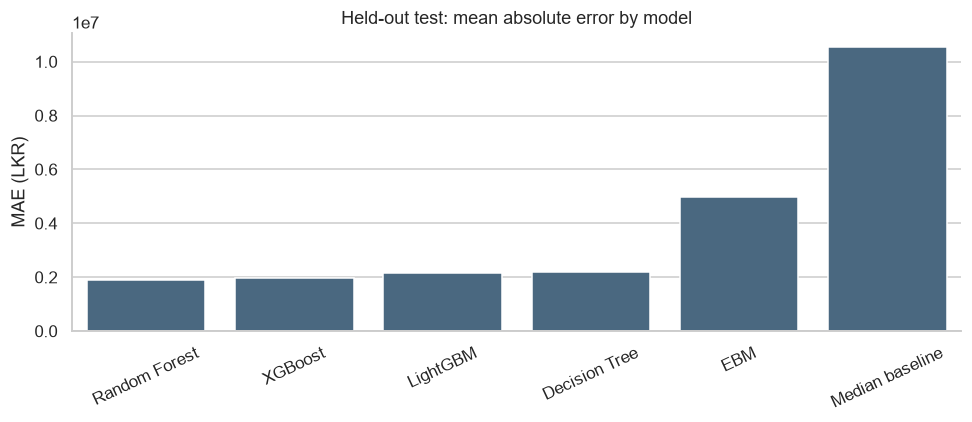

In [14]:
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=test_metrics,x='Model',y='MAE_LKR',color='#416989',ax=ax)
ax.set(title='Held-out test: mean absolute error by model',xlabel='',ylabel='MAE (LKR)')
ax.tick_params(axis='x',labelrotation=25)
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'test_model_comparison.png',dpi=160,bbox_inches='tight')

## 9. Prediction error analysis

Residuals and MAE are examined across observed asking-price bands for the selected model and for EBM, showing where each model's errors concentrate.

PriceBand,Records,MAE_LKR,EBM_MAE_LKR,MedianPriceLKR
Below 10M,601,"591,597","3,597,847","6,900,000"
10M–30M,514,"1,383,397","3,919,748","14,350,000"
30M–100M,156,"7,146,686","9,340,922","42,750,000"
100M+,14,"25,055,715","55,310,183","147,500,000"


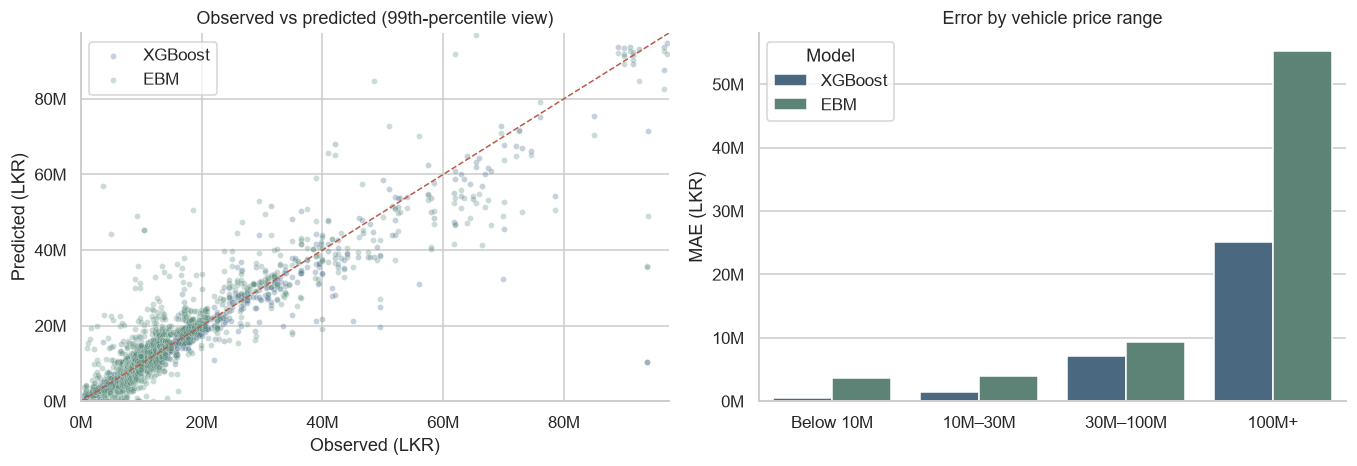

In [15]:
predictions_df=X_test.reset_index(drop=True).copy()
predictions_df['ActualLKR']=y_test.to_numpy()
predictions_df['PredictedLKR']=selected_preds
predictions_df['AbsoluteErrorLKR']=np.abs(predictions_df.ActualLKR-predictions_df.PredictedLKR)
predictions_df['ResidualLKR']=predictions_df.ActualLKR-predictions_df.PredictedLKR
predictions_df['EBM_PredictedLKR']=ebm_preds
predictions_df['EBM_AbsoluteErrorLKR']=np.abs(predictions_df.ActualLKR-predictions_df.EBM_PredictedLKR)
predictions_df['PriceBand']=pd.cut(predictions_df.ActualLKR,
    bins=[0,10e6,30e6,100e6,np.inf],right=False,
    labels=['Below 10M','10M–30M','30M–100M','100M+'])
error_bands=predictions_df.groupby('PriceBand',observed=True).agg(
    Records=('ActualLKR','size'),MAE_LKR=('AbsoluteErrorLKR','mean'),
    EBM_MAE_LKR=('EBM_AbsoluteErrorLKR','mean'),
    MedianPriceLKR=('ActualLKR','median')).reset_index()
display(error_bands.style.format({'MAE_LKR':'{:,.0f}','EBM_MAE_LKR':'{:,.0f}',
                                  'MedianPriceLKR':'{:,.0f}'}).hide(axis='index'))
model_colors={winning_name:'#416989','EBM':'#558a77'}
fig,ax=plt.subplots(1,2,figsize=(12.5,4.4))
limit=np.quantile(predictions_df[['ActualLKR','PredictedLKR']].to_numpy(),.99)
for column,label in [('PredictedLKR',winning_name),('EBM_PredictedLKR','EBM')]:
    sns.scatterplot(data=predictions_df,x='ActualLKR',y=column,color=model_colors[label],
                    alpha=.3,s=15,ax=ax[0],label=label)
ax[0].plot([0,limit],[0,limit],'--',color='#b85c48',lw=1)
ax[0].set(xlim=(0,limit),ylim=(0,limit),title='Observed vs predicted (99th-percentile view)',
          xlabel='Observed (LKR)',ylabel='Predicted (LKR)')
ax[0].xaxis.set_major_formatter(MILLIONS);ax[0].yaxis.set_major_formatter(MILLIONS)
band_long=error_bands.melt(id_vars='PriceBand',value_vars=['MAE_LKR','EBM_MAE_LKR'],
                           var_name='Model',value_name='MAE')
band_long['Model']=band_long.Model.map({'MAE_LKR':winning_name,'EBM_MAE_LKR':'EBM'})
sns.barplot(data=band_long,x='PriceBand',y='MAE',hue='Model',palette=model_colors,ax=ax[1])
ax[1].set(title='Error by vehicle price range',xlabel='',ylabel='MAE (LKR)')
ax[1].yaxis.set_major_formatter(MILLIONS)
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'test_model_diagnostics.png',dpi=160,bbox_inches='tight')
predictions_df.to_csv(OUTPUT_DIR/'test_price_predictions.csv',index=False)
error_bands.to_csv(OUTPUT_DIR/'error_by_price_band.csv',index=False)

## 10. Explainable AI

The selected model is a black box: each prediction passes through one-hot encoding, hundreds of trees and a log back-transform, so it can only be explained *post hoc*. EBM is explainable *by construction*. The analysis therefore pairs the two models around three questions:

| Question | Selected black-box model | Glass-box EBM |
|---|---|---|
| Which features matter overall? | Permutation importance (10.1) | Permutation importance and built-in term importance (10.1) |
| How does the price respond to a feature? | — | Learned shape functions (10.2) |
| Why this price for this vehicle? | — | Exact additive decomposition (10.3) |

Applying the same model-agnostic permutation method to both models makes their global explanations directly comparable. None of these explanations establishes causality: they describe what each model has learned from advertised prices.

### 10.1 Global feature importance

Permutation importance shuffles one feature at a time in a validation sample (450 listings, models fitted on the training partition) and records the resulting increase in MAE. EBM's built-in importance is the mean absolute contribution of each term in the final EBM, measured in million LKR. Because that is a different quantity, it is plotted separately.

Feature,MAE_Increase_LKR,SD_LKR,EBM_MAE_Increase_LKR,EBM_SD_LKR
EngineCC,"11,154,196","453,540","8,579,709","247,067"
ManufactureYear,"4,095,940","99,233","3,946,764","46,699"
Brand,"2,733,700","24,925","2,145,009","290,990"
MileageKM,"1,891,779","116,737","1,628,496","134,684"
Model,"872,643","10,210","2,783,418","382,275"
Transmission,"779,963","41,284","-1,996","2,111"
BodyType,"714,051","164,546","44,974","7,813"
FuelType,"528,537","11,643","629,223","33,781"
Edition,"112,773","20,339","408,525","50,442"
Negotiable,"40,423","10,585","7,903",540


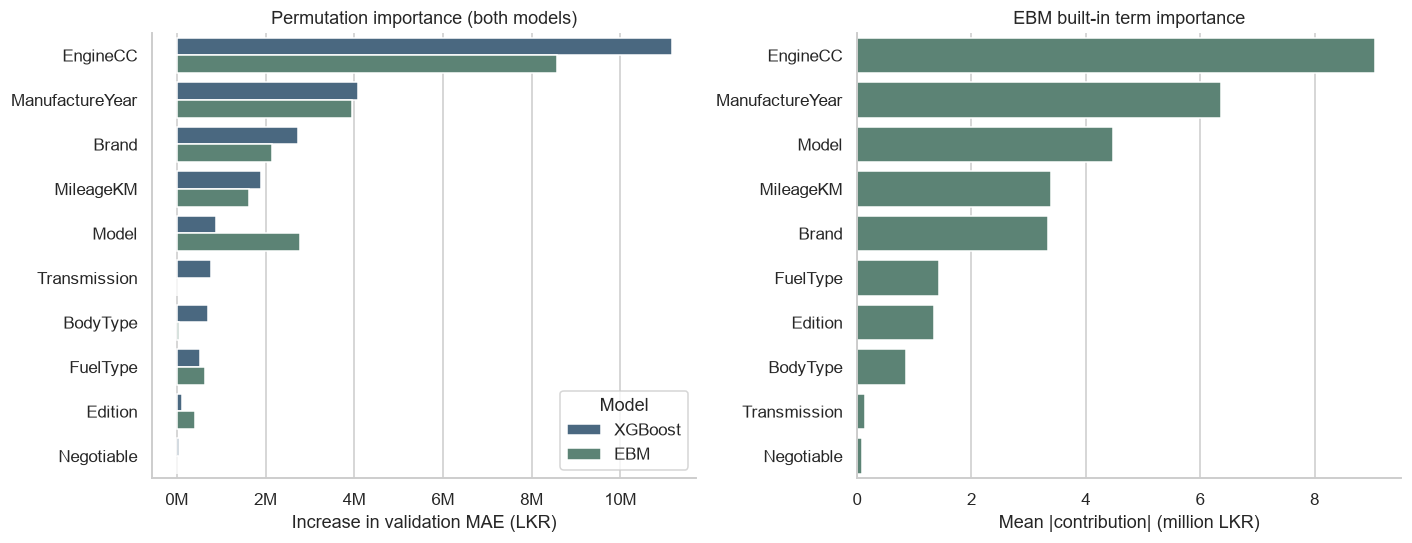

In [16]:
rng=np.random.default_rng(SEED)
ix=rng.choice(len(X_val),min(450,len(X_val)),replace=False)

def permutation_scores(model):
    result=permutation_importance(model,X_val.iloc[ix],y_val.iloc[ix],
        scoring='neg_mean_absolute_error',n_repeats=2,random_state=SEED,n_jobs=1)
    return result.importances_mean,result.importances_std

selected_mean,selected_sd=permutation_scores(model_options[winning_name])
ebm_mean,ebm_sd=permutation_scores(model_options['EBM'])
importance_df=pd.DataFrame({'Feature':FEATURES,
    'MAE_Increase_LKR':selected_mean,'SD_LKR':selected_sd,
    'EBM_MAE_Increase_LKR':ebm_mean,'EBM_SD_LKR':ebm_sd,
}).sort_values('MAE_Increase_LKR',ascending=False)
display(importance_df.style.format({c:'{:,.0f}' for c in importance_df.columns[1:]}).hide(axis='index'))

ebm_estimator=ebm_model.regressor_
ebm_global_importance=pd.DataFrame({
    'Feature':list(ebm_estimator.term_names_),
    'MeanAbsoluteContribution_MillionLKR':np.asarray(ebm_estimator.term_importances(),dtype=float),
}).sort_values('MeanAbsoluteContribution_MillionLKR',ascending=False)

fig,axes=plt.subplots(1,2,figsize=(13,5.1))
importance_long=importance_df.melt(id_vars='Feature',
    value_vars=['MAE_Increase_LKR','EBM_MAE_Increase_LKR'],var_name='Model',value_name='MAE increase')
importance_long['Model']=importance_long.Model.map(
    {'MAE_Increase_LKR':winning_name,'EBM_MAE_Increase_LKR':'EBM'})
sns.barplot(data=importance_long,y='Feature',x='MAE increase',hue='Model',
            palette=model_colors,ax=axes[0])
axes[0].set(title='Permutation importance (both models)',
            xlabel='Increase in validation MAE (LKR)',ylabel='')
axes[0].xaxis.set_major_formatter(MILLIONS)
sns.barplot(data=ebm_global_importance,y='Feature',x='MeanAbsoluteContribution_MillionLKR',
            color=model_colors['EBM'],ax=axes[1])
axes[1].set(title='EBM built-in term importance',
            xlabel='Mean |contribution| (million LKR)',ylabel='')
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'feature_importance.png',dpi=160,bbox_inches='tight')
importance_df.to_csv(OUTPUT_DIR/'feature_importance.csv',index=False)
ebm_global_importance.to_csv(OUTPUT_DIR/'ebm_global_importance.csv',index=False)

### 10.2 How EBM prices individual features

Each EBM term is a learned *shape function*: the amount (in million LKR) that the feature adds to or subtracts from the baseline at every value. Because the model is additive, these curves *are* the model rather than an approximation of it. The plots show the three numeric features over the central 98% of training values; the shaded band shows the variation across EBM's bagged models.

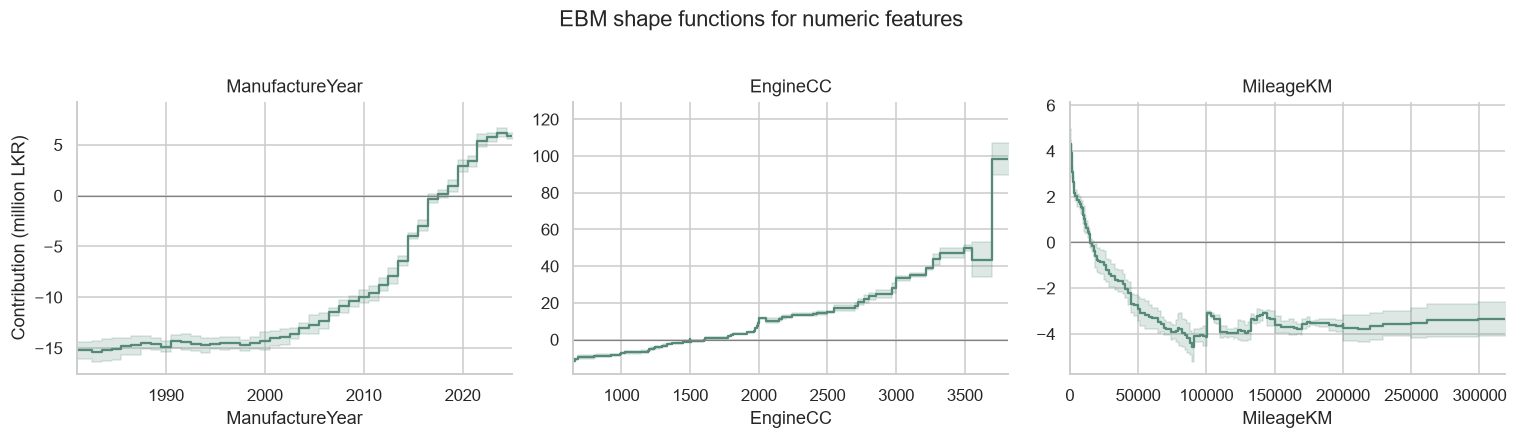

In [17]:
global_explanation=ebm_estimator.explain_global()
term_names=list(ebm_estimator.term_names_)
fig,axes=plt.subplots(1,len(NUM),figsize=(14,3.9))
for ax,feature in zip(axes,NUM):
    shape=global_explanation.data(term_names.index(feature))
    edges=np.asarray(shape['names'],dtype=float)
    def per_edge(values):
        return np.append(values,values[-1])
    ax.fill_between(edges,per_edge(shape['lower_bounds']),per_edge(shape['upper_bounds']),
                    step='post',color=model_colors['EBM'],alpha=.2)
    ax.step(edges,per_edge(shape['scores']),where='post',color=model_colors['EBM'])
    ax.axhline(0,color='gray',lw=.8)
    ax.set_xlim(*np.nanpercentile(X_trainval[feature],[1,99]))
    ax.set(title=feature,xlabel=feature,ylabel='Contribution (million LKR)' if ax is axes[0] else '')
fig.suptitle('EBM shape functions for numeric features',y=1.02)
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'ebm_shape_functions.png',dpi=160,bbox_inches='tight')

### 10.3 Explaining one prediction

For a typical held-out listing (the vehicle whose asking price is closest to the test-set median), the selected model's prediction is shown next to EBM's, and EBM's estimate is decomposed into its baseline (intercept) plus one contribution per feature, in rupees. Positive contributions raise the estimate above the baseline and negative ones lower it. The decomposition reconstructs EBM's unclipped prediction exactly; it explains EBM only, not the black-box model. The listing is chosen by price alone, without reference to any model's error, and plays no part in model selection.

Observed asking price,XGBoost prediction,EBM prediction
"10,975,000","11,585,893","13,486,189"


EBM baseline (intercept): Rs. 17,441,261


Feature,Value,Contribution_LKR
EngineCC,990.0,"-8,214,569"
ManufactureYear,2025,"+5,833,280"
Model,Roomy,"-5,781,030"
MileageKM,0.0,"+4,910,504"
Brand,Toyota,"-1,390,787"
FuelType,Petrol,"+755,418"
Transmission,Automatic,"-79,628"
BodyType,Mpv,"+66,715"
Negotiable,Yes,"-54,976"
Edition,Gt Custom Turbo B/Ne,+0


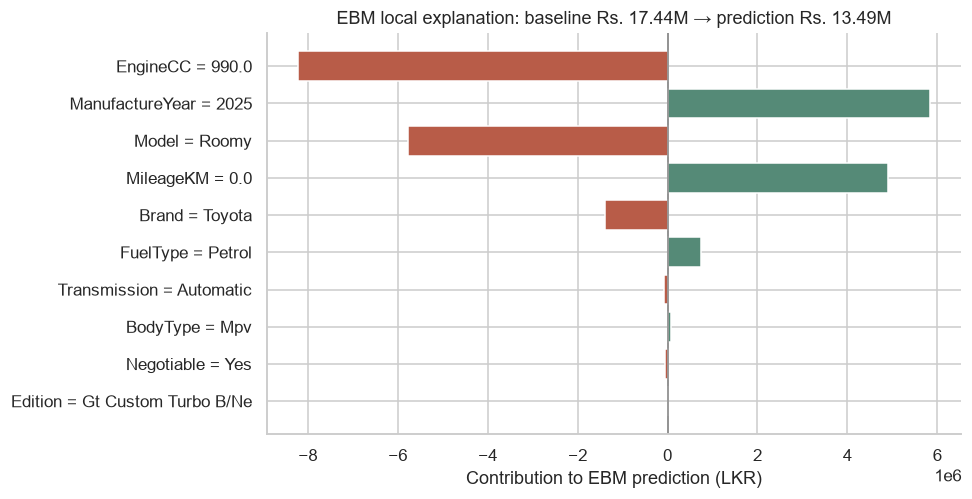

In [18]:
def ebm_local_contributions(ebm, record):
    """Baseline and per-feature contributions (LKR) that sum to EBM's prediction."""
    names=list(ebm.term_names_)
    contributions=pd.DataFrame({
        'Feature':names,
        'Value':record.iloc[0][names].astype(str).to_numpy(),
        'Contribution_LKR':np.asarray(ebm.eval_terms(record),dtype=float).ravel()*EBM_PRICE_UNIT,
    }).sort_values('Contribution_LKR',key=lambda s:s.abs(),ascending=False)
    baseline=float(np.asarray(ebm.intercept_).ravel()[0])*EBM_PRICE_UNIT
    return baseline,contributions

position=int(np.argmin(np.abs(y_test.to_numpy()-y_test.median())))
example=X_test.iloc[[position]]
baseline_lkr,local_xai=ebm_local_contributions(ebm_estimator,example)
ebm_example_lkr=float(ebm_model.predict(example)[0])
assert np.isclose(baseline_lkr+local_xai.Contribution_LKR.sum(),ebm_example_lkr,atol=1.0)

display(pd.DataFrame({
    'Observed asking price':[float(y_test.iloc[position])],
    f'{winning_name} prediction':[max(float(selected_model.predict(example)[0]),0)],
    'EBM prediction':[max(ebm_example_lkr,0)],
}).style.format('{:,.0f}').hide(axis='index'))
print(f'EBM baseline (intercept): Rs. {baseline_lkr:,.0f}')
display(local_xai.style.format({'Contribution_LKR':'{:+,.0f}'}).hide(axis='index'))
local_xai.to_csv(OUTPUT_DIR/'ebm_example_local_explanation.csv',index=False)

ordered=local_xai.iloc[::-1]
fig,ax=plt.subplots(figsize=(9,4.7))
ax.barh(ordered.Feature+' = '+ordered.Value,ordered.Contribution_LKR,
        color=np.where(ordered.Contribution_LKR>=0,model_colors['EBM'],'#b85c48'))
ax.axvline(0,linewidth=1,color='gray')
ax.set(title=f'EBM local explanation: baseline Rs. {baseline_lkr/1e6:,.2f}M → '
             f'prediction Rs. {ebm_example_lkr/1e6:,.2f}M',
       xlabel='Contribution to EBM prediction (LKR)',ylabel='')
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'ebm_local_explanation.png',dpi=160,bbox_inches='tight')

## 11. Model export and inference verification

Two models are exported: the selected pipeline, which serves price estimates, and the fitted EBM, which serves glass-box estimates and local explanations in the Streamlit app. Both are reloaded and checked against the in-memory models.

In [19]:
MODEL_PATH = OUTPUT_DIR / 'trained_vehicle_price_model.pkl'
EBM_MODEL_PATH = OUTPUT_DIR / 'ebm_vehicle_price_model.pkl'
joblib.dump(selected_model, MODEL_PATH)
# The app uses the bare EBM estimator (output in million LKR) for estimates and explanations.
joblib.dump(ebm_estimator, EBM_MODEL_PATH)

reloaded_model = joblib.load(MODEL_PATH)
reloaded_ebm = joblib.load(EBM_MODEL_PATH)
assert np.allclose(reloaded_model.predict(X_test.iloc[:3]), selected_model.predict(X_test.iloc[:3]))
assert np.allclose(reloaded_ebm.predict(X_test.iloc[:3]) * EBM_PRICE_UNIT,
                   ebm_model.predict(X_test.iloc[:3]))
print('Saved selected model:', MODEL_PATH)
print('Saved EBM:', EBM_MODEL_PATH)

Saved selected model: C:\Users\wiaklk\OneDrive - IFS\Documents\Msc\Sem2\AML\Sri_Lanka_Vehicle_Price_Prediction_Project\vehicle_ml_outputs\trained_vehicle_price_model.pkl
Saved EBM: C:\Users\wiaklk\OneDrive - IFS\Documents\Msc\Sem2\AML\Sri_Lanka_Vehicle_Price_Prediction_Project\vehicle_ml_outputs\ebm_vehicle_price_model.pkl


### Example prediction

An illustrative new vehicle checks that both exported models accept the raw feature schema.

In [20]:
new_vehicle = pd.DataFrame([{
    'Brand': 'Toyota',
    'Model': 'Aqua',
    'Edition': 'Unknown',
    'Transmission': 'Automatic',
    'FuelType': 'Hybrid',
    'BodyType': 'Hatchback',
    'Negotiable': 'Yes',
    'ManufactureYear': 2017,
    'EngineCC': 1500,
    'MileageKM': 85000,
}])
display(pd.DataFrame({
    'Vehicle': ['Toyota Aqua (illustrative input)'],
    f'{winning_name} (LKR)': [max(float(reloaded_model.predict(new_vehicle)[0]), 0)],
    'EBM (LKR)': [max(float(reloaded_ebm.predict(new_vehicle[FEATURES])[0]) * EBM_PRICE_UNIT, 0)],
}).style.format({f'{winning_name} (LKR)': '{:,.0f}', 'EBM (LKR)': '{:,.0f}'}).hide(axis='index'))

Vehicle,XGBoost (LKR),EBM (LKR)
Toyota Aqua (illustrative input),"9,653,529","13,027,813"


In [21]:
metadata = {
    'source': 'Vehicle listings scraped from ikman.lk (advertised asking prices)',
    'model': winning_name,
    'selected_on': 'validation MAE only',
    'target': TARGET,
    'numeric_features': NUM,
    'categorical_features': CAT,
    'n_raw_cleaned': int(len(df)),
    'split_counts': {
        'train': len(train_idx),
        'validation': len(val_idx),
        'test': len(test_idx),
    },
    'test_metrics': test_metrics.to_dict('records'),
    'interpretable_model': {
        'name': 'EBM',
        'file': EBM_MODEL_PATH.name,
        'output_unit': 'million LKR (identity link); multiply by 1,000,000 for LKR',
        'hyperparameters': ebm_estimator.get_params(),
    },
    'price_unit': 'LKR',
    'note': 'Predicts listing asking prices, not transacted market values',
}
(OUTPUT_DIR / 'model_metadata.json').write_text(
    json.dumps(metadata, indent=2, default=str), encoding='utf-8'
)
print('Saved metadata:', OUTPUT_DIR / 'model_metadata.json')

Saved metadata: C:\Users\wiaklk\OneDrive - IFS\Documents\Msc\Sem2\AML\Sri_Lanka_Vehicle_Price_Prediction_Project\vehicle_ml_outputs\model_metadata.json


## 12. Conclusions

- **Accuracy.** The tree ensembles clearly outperform the median baseline and the single Decision Tree. The default-settings XGBoost had the lowest validation MAE and is the deployed model. On the held-out test set its error is close to Random Forest's (which scores marginally lower), and the selection is not revised on test results.
- **The cost of a glass box.** EBM is markedly less accurate than the black-box ensembles, with its MAE roughly two and a half times the selected model's and higher in every price band. A notable share of its test predictions fall at or below zero and are clipped (count below). Because EBM adds per-feature effects on the raw price scale, the large deductions for an old year or a small engine can outweigh the baseline for cheap vehicles. The log-target tree models instead scale such effects with the vehicle's value, and they also capture feature interactions that `interactions=0` excludes.
- **What the explanations agree on.** Permutation importance ranks the same five features (engine capacity, manufacture year, brand, mileage and model) highest for both models, so EBM's transparent account describes much the same drivers that the black-box model relies on. The models differ on transmission and body type, which matter to XGBoost but barely to EBM, probably because EBM's per-model term already absorbs them. EBM's shape functions make the learned pricing logic explicit: prices rise steeply for vehicles built after about 2010, increase with engine capacity, and fall sharply over the first ~50,000 km before levelling off.
- **Implication.** The selected black-box model is the better price estimator, while EBM is the better instrument for communicating *why* prices vary. Using both together, as the Streamlit app does, provides accurate estimates and a faithful view of the drivers behind them. Natural next steps would be an EBM on a log-price scale or with pairwise interactions, which could narrow the accuracy gap while keeping the model transparent.


In [22]:
summary=test_metrics.set_index('Model').loc[[winning_name,'EBM']]
display(pd.DataFrame({
    'Role':['Deployed price model (validation-selected)','Glass-box comparator'],
    'Test MAE (LKR)':summary.MAE_LKR.map('{:,.0f}'.format).to_numpy(),
    'Test RMSE (LKR)':summary.RMSE_LKR.map('{:,.0f}'.format).to_numpy(),
    'Test R²':summary.R2.map('{:.3f}'.format).to_numpy(),
    'Median APE':summary.Median_APE_pct.map('{:.1f}%'.format).to_numpy(),
    'Explanations':['Post-hoc: permutation importance',
                    'Built-in: term importance, shape functions, exact local decomposition'],
}, index=summary.index).style)
print(f'Held-out test listings: {len(y_test):,}')
print(f'EBM test predictions at or below zero (clipped to 0): {int((ebm_preds<=0).sum())} of {len(ebm_preds):,}')

,Role,Test MAE (LKR),Test RMSE (LKR),Test R²,Median APE,Explanations
Model,,,,,,
XGBoost,Deployed price model (validation-selected),"1,970,645","6,678,516",0.901,6.1%,Post-hoc: permutation importance
EBM,Glass-box comparator,"4,987,224","10,511,416",0.755,23.9%,"Built-in: term importance, shape functions, exact local decomposition"


Held-out test listings: 1,285
EBM test predictions at or below zero (clipped to 0): 103 of 1,285


**Limitations and responsible use.** Listing dates and advertisement IDs are unavailable, reposted listings may remain, errors increase for high-value vehicles, and the brand/model distribution is imbalanced. Feature importances, shape functions and contributions describe model behaviour, not causal effects. The Streamlit app reads the files saved by this notebook; re-run it to refresh them.